decision tree

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier,plot_tree
from sklearn.metrics import accuracy_score,classification_report
import matplotlib.pyplot as plt
print("Libraries imported successfully")

Libraries imported successfully


In [2]:
from google.colab import files
uploaded = files.upload()
file_name=next(iter(uploaded))
df=pd.read_csv(file_name)
print("Dataset imported successfully")
display(df.head())

Saving students.csv to students.csv
Dataset imported successfully


,StudyHours,Attendance,PrevMarks,Result
0,6,85,78,Pass
1,2,55,35,Fail
2,7,90,88,Pass
3,3,60,42,Fail
4,5,75,65,Pass


In [3]:
print(df.shape)
print("\nMissing Values")
print(df.isnull().sum)
print("\nResult Counts")
print(df['Result'].value_counts())
print("\nDataset information")
df.info()

(10, 4)

Missing Values
<bound method DataFrame.sum of    StudyHours  Attendance  PrevMarks  Result
0       False       False      False   False
1       False       False      False   False
2       False       False      False   False
3       False       False      False   False
4       False       False      False   False
5       False       False      False   False
6       False       False      False   False
7       False       False      False   False
8       False       False      False   False
9       False       False      False   False>

Result Counts
Result
Pass    5
Fail    5
Name: count, dtype: int64

Dataset information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   StudyHours  10 non-null     int64 
 1   Attendance  10 non-null     int64 
 2   PrevMarks   10 non-null     int64 
 3   Result      10 non-null     object
dtypes: int64(3), o

separate x and y

In [4]:
x=df[['StudyHours','Attendance','PrevMarks']]
y=df['Result']
print("Input features")
display(x.head())
print("\nTarget variable")
display(y.head())

Input features


,StudyHours,Attendance,PrevMarks
0,6,85,78
1,2,55,35
2,7,90,88
3,3,60,42
4,5,75,65



Target variable


,Result
0,Pass
1,Fail
2,Pass
3,Fail
4,Pass


In [7]:
X_tr,X_te,y_tr,y_te=train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)
print("Training records: ",len(X_tr))
print("Testing records: ",len(X_te))

Training records:  8
Testing records:  2


In [8]:
tree_clf=DecisionTreeClassifier(criterion='entropy',max_depth=3,random_state=42)
tree_clf.fit(X_tr,y_tr)
print("Decision tree model trained successfully")

Decision tree model trained successfully


make predictions

In [9]:
y_pred=tree_clf.predict(X_te)
comparison=pd.DataFrame({'Actual':y_te.values,'Predicted':y_pred})
display(comparison)
print("Predictions made successfully")

,Actual,Predicted
0,Fail,Pass
1,Pass,Pass


Predictions made successfully


evaluate the model

In [10]:
print("Accuracy:",round(accuracy_score(y_te,y_pred),3))
print("\nClassification Report")
print(classification_report(y_te,y_pred,zero_division=0))

Accuracy: 0.5

Classification Report
              precision    recall  f1-score   support

        Fail       0.00      0.00      0.00         1
        Pass       0.50      1.00      0.67         1

    accuracy                           0.50         2
   macro avg       0.25      0.50      0.33         2
weighted avg       0.25      0.50      0.33         2



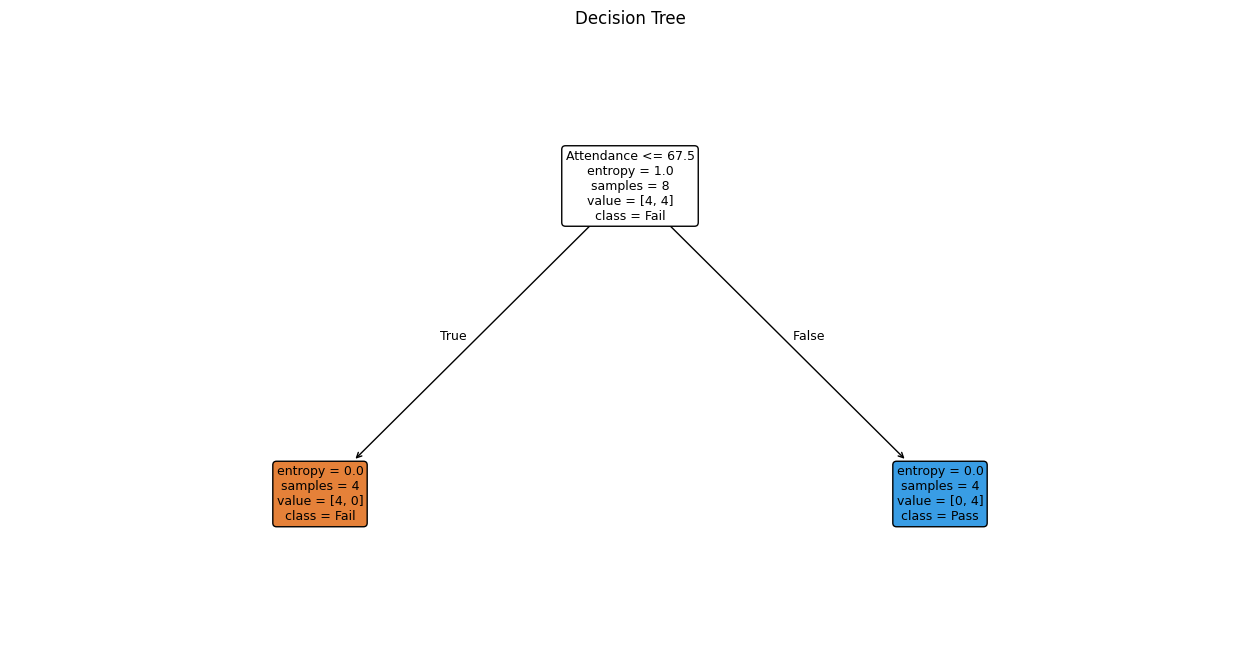

In [15]:
plt.figure(figsize=(16,8))
plot_tree(tree_clf,filled=True,feature_names=x.columns,class_names=['Fail','Pass'],rounded=True,fontsize=9)
plt.title("Decision Tree")
plt.show()